# Can Saliency Maps Flag Chest Radiograph Classifier Errors at a New Hospital? An External Validation Study
## Data Preprocessing and EDA
## Aashish Chapagai (Last Edited: September 2026)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import GroupShuffleSplit
from multiprocessing import Pool

os.makedirs('models', exist_ok=True)
os.makedirs('figures', exist_ok=True)

IMAGE_DIR = 'images/'
IMG_SIZE = 320
TEST_FRACTION = 0.20
SPLIT_SEARCH = 50
RESAMPLE = getattr(Image, 'Resampling', Image).BICUBIC
WORKERS = max(1, os.cpu_count() - 2)

In [2]:
dataset = pd.read_csv('Dataset.csv')

dataset = dataset.drop(columns=['OriginalImage[Width', 'Height]', 'Follow-up #'])

In [3]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 8 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Image Index                  112120 non-null  str    
 1   Finding Labels               112120 non-null  str    
 2   Patient ID                   112120 non-null  int64  
 3   Patient Age                  112120 non-null  int64  
 4   Patient Sex                  112120 non-null  str    
 5   View Position                112120 non-null  str    
 6   OriginalImagePixelSpacing[x  112120 non-null  float64
 7   y]                           112120 non-null  float64
dtypes: float64(2), int64(2), str(4)
memory usage: 6.8 MB


In [4]:
dataset = dataset.drop_duplicates()
remaining_duplicates = dataset.duplicated().sum()
print(f"Remaining duplicate count: {remaining_duplicates}")

Remaining duplicate count: 0


In [5]:
class_counts = dataset['Finding Labels'].str.split('|').explode().value_counts()
print(class_counts)

Finding Labels
No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
Name: count, dtype: int64


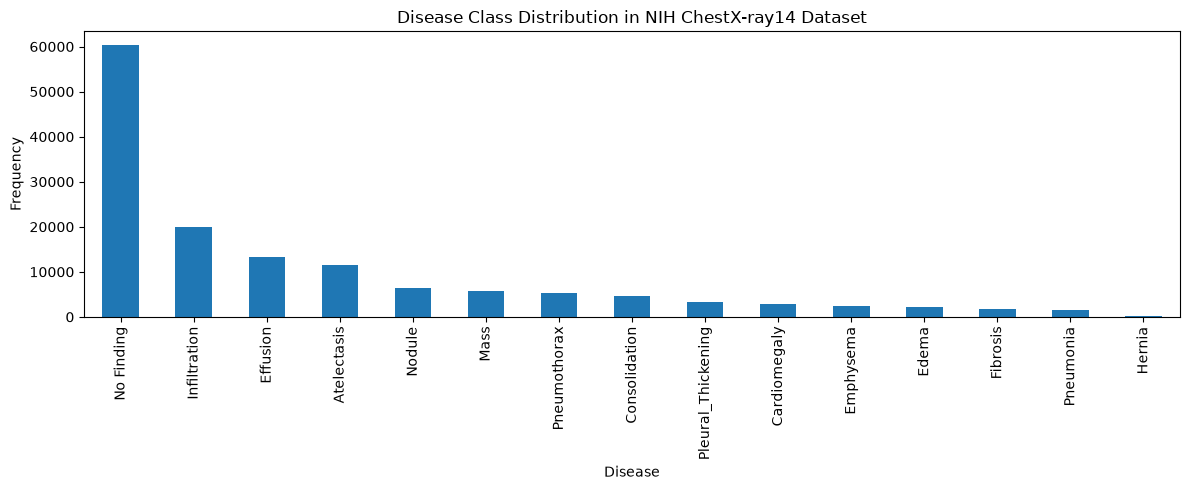

In [6]:
plt.figure(figsize=(12, 5))
class_counts.plot(kind='bar')
plt.title('Disease Class Distribution in NIH ChestX-ray14 Dataset')
plt.xlabel('Disease')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('figures/disease_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [7]:
disease_classes = sorted(set(class_counts.index) - {'No Finding'})

print(f"Disease classes found: {len(disease_classes)}")
print(f"Classes: {', '.join(disease_classes)}")

Disease classes found: 14
Classes: Atelectasis, Cardiomegaly, Consolidation, Edema, Effusion, Emphysema, Fibrosis, Hernia, Infiltration, Mass, Nodule, Pleural_Thickening, Pneumonia, Pneumothorax


In [8]:
filtered_dataset = dataset.drop_duplicates(subset=['Image Index']).reset_index(drop=True)

on_disk = filtered_dataset['Image Index'].map(lambda f: os.path.exists(os.path.join(IMAGE_DIR, f)))

images_present = int(on_disk.sum())
print(f"Found {images_present} images on disk, {len(filtered_dataset) - images_present} listed but absent.")

filtered_dataset = filtered_dataset[on_disk].reset_index(drop=True)

findings = filtered_dataset['Finding Labels'].str.split('|').map(lambda f: [x for x in f if x != 'No Finding'])
encoded_labels = MultiLabelBinarizer(classes=disease_classes).fit_transform(findings).astype(np.uint8)

patient_ids = filtered_dataset['Patient ID'].astype(str).to_numpy()
print(f"Dataset: {len(filtered_dataset)} images, {len(set(patient_ids))} patients, label matrix {encoded_labels.shape}")

Found 112120 images on disk, 0 listed but absent.
Dataset: 112120 images, 30805 patients, label matrix (112120, 14)


In [9]:
def marginal_divergence(labels, rows_a, rows_b):
    return 0.5 * np.abs(labels[rows_a].mean(axis=0) - labels[rows_b].mean(axis=0)).sum()

candidates = []
for seed in range(SPLIT_SEARCH):
    gss = GroupShuffleSplit(n_splits=1, test_size=TEST_FRACTION, random_state=seed)
    tr, te = next(gss.split(np.zeros(len(filtered_dataset)), encoded_labels, groups=patient_ids))
    candidates.append((marginal_divergence(encoded_labels, tr, te), seed, tr, te))

candidates.sort(key=lambda c: c[0])
best_divergence, SPLIT_SEED, train_idx, test_idx = candidates[0]
worst_divergence = candidates[-1][0]

print(f"Searched {SPLIT_SEARCH} candidate splits.")
print(f"Label divergence ranged from {best_divergence:.5f} to {worst_divergence:.5f}.")
print(f"Selected seed {SPLIT_SEED}, which gave the lowest divergence.")

shared_patients = set(patient_ids[train_idx]).intersection(patient_ids[test_idx])
print(f"Patients appearing in both train and test: {len(shared_patients)}")

print(f"Train split: {len(train_idx)} images from {len(set(patient_ids[train_idx]))} patients.")
print(f"Test split: {len(test_idx)} images from {len(set(patient_ids[test_idx]))} patients.")

Searched 50 candidate splits.
Label divergence ranged from 0.00937 to 0.02960.
Selected seed 4, which gave the lowest divergence.
Patients appearing in both train and test: 0
Train split: 90286 images from 24644 patients.
Test split: 21834 images from 6161 patients.


In [10]:
filenames = filtered_dataset['Image Index'].to_numpy()

def load_image(filename):
    with Image.open(os.path.join(IMAGE_DIR, filename)) as handle:
        image = handle.convert('L').resize((IMG_SIZE, IMG_SIZE), RESAMPLE)
    return np.asarray(image, dtype=np.uint8)[..., None]

print(f"Decoding images across {WORKERS} worker processes.")

with Pool(WORKERS) as pool:
    for split, rows in (('train', train_idx), ('test', test_idx)):
        images = np.lib.format.open_memmap(f'models/X_{split}.npy', mode='w+', dtype=np.uint8, shape=(len(rows), IMG_SIZE, IMG_SIZE, 1))

        for position, image in enumerate(pool.imap(load_image, filenames[rows], chunksize=64)):
            images[position] = image
            if position % 5000 == 0:
                print(f"  Loading {split}: {position}/{len(rows)}", flush=True)

        images.flush()
        del images

        np.save(f'models/Y_{split}.npy', encoded_labels[rows])
        np.save(f'models/{split}_patient_ids.npy', patient_ids[rows])
        filtered_dataset.iloc[rows].to_csv(f'models/metadata_{split}.csv', index=False)
        print(f"  Saved {split}: {len(rows)} images, {os.path.getsize(f'models/X_{split}.npy') / 1e9:.2f} GB")

Decoding images across 18 worker processes.
  Loading train: 0/90286
  Loading train: 5000/90286
  Loading train: 10000/90286
  Loading train: 15000/90286
  Loading train: 20000/90286
  Loading train: 25000/90286
  Loading train: 30000/90286
  Loading train: 35000/90286
  Loading train: 40000/90286
  Loading train: 45000/90286
  Loading train: 50000/90286
  Loading train: 55000/90286
  Loading train: 60000/90286
  Loading train: 65000/90286
  Loading train: 70000/90286
  Loading train: 75000/90286
  Loading train: 80000/90286
  Loading train: 85000/90286
  Loading train: 90000/90286
  Saved train: 90286 images, 9.25 GB
  Loading test: 0/21834
  Loading test: 5000/21834
  Loading test: 10000/21834
  Loading test: 15000/21834
  Loading test: 20000/21834
  Saved test: 21834 images, 2.24 GB


In [11]:
np.save('models/disease_classes.npy', np.array(disease_classes))

train_prevalence = encoded_labels[train_idx].mean(axis=0)
test_prevalence = encoded_labels[test_idx].mean(axis=0)
population = encoded_labels.mean(axis=0)

print(f"\n{'Class':<20}{'Train %':>9}{'Test %':>9}{'Test n':>8}{'Drift':>9}")
for c, name in enumerate(disease_classes):
    drift = 100 * (test_prevalence[c] - population[c]) / population[c]
    print(f"{name:<20}{100 * train_prevalence[c]:>9.2f}{100 * test_prevalence[c]:>9.2f}{int(encoded_labels[test_idx, c].sum()):>8}{drift:>8.1f}%")
print(f"\nWrote {IMG_SIZE}px uint8 arrays using split seed {SPLIT_SEED} and BICUBIC resampling.")


Class                 Train %   Test %  Test n    Drift
Atelectasis             10.31    10.31    2251     0.0%
Cardiomegaly             2.48     2.47     540    -0.1%
Consolidation            4.23     3.88     847    -6.8%
Edema                    2.01     2.22     484     7.9%
Effusion                11.85    11.99    2618     1.0%
Emphysema                2.23     2.30     502     2.5%
Fibrosis                 1.50     1.52     332     1.1%
Hernia                   0.21     0.15      33   -25.3%
Infiltration            17.72    17.83    3893     0.5%
Mass                     5.13     5.28    1152     2.3%
Nodule                   5.64     5.68    1240     0.6%
Pleural_Thickening       2.98     3.17     692     5.0%
Pneumonia                1.28     1.26     276    -1.0%
Pneumothorax             4.83     4.31     940    -9.0%

Wrote 320px uint8 arrays using split seed 4 and BICUBIC resampling.
